### **Multiclass Classification with Logistic Regression**

**Dataset:** Palmer Penguins - `penguins.csv`
**Target:** `species` - Adelie / Chinstrap / Gentoo → **3 classes = multiclass classification**

Same preprocessing pipeline as the binary example; the differences are highlighted with **[MULTICLASS]**.

### 1. Setup

In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, roc_auc_score,
)

from imblearn.over_sampling import SMOTENC

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', "{:.3f}".format)

### 2. Data Loading & basic cleanup

In [3]:
df = pd.read_csv("penguins.csv")
# (same data as sns.load_dataset("penguins"), saved locally)
print("Shape of the dataset:", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Shape of the dataset: (344, 7)
Columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.100,18.700,181.000,3750.000,MALE
1,Adelie,Torgersen,39.500,17.400,186.000,3800.000,FEMALE
2,Adelie,Torgersen,40.300,18.000,195.000,3250.000,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.700,19.300,193.000,3450.000,FEMALE


In [4]:
target_col = "species"
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_cols = ["island", "sex"]

# clean sex column - raw file uses MALE / FEMALE -> Male / Female,
# anything else becomes NaN
df["sex"] = df["sex"].str.title()
df["sex"] = df["sex"].where(df["sex"].isin(["Male", "Female"]))

# drop rows where ALL measurements are missing - nothing to learn from them
# (row-level cleanup, does not use the target, so safe before the split)
before = len(df)
df = df.dropna(subset=num_cols, how="all").reset_index(drop=True)
print(f"Dropped {before - len(df)} empty rows -> {df.shape}")

Dropped 2 empty rows -> (342, 7)


### 3. Quick EDA

In [5]:
print("Target distribution:")
print(df[target_col].value_counts())
print(df[target_col].value_counts(normalize=True))
print("-" * 40)
print("Missing values per column:")
print(df.isnull().sum())

Target distribution:
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64
species
Adelie      0.442
Gentoo      0.360
Chinstrap   0.199
Name: proportion, dtype: float64
----------------------------------------
Missing values per column:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64


In [6]:
# species per island - island alone is a strong hint
pd.crosstab(df["island"], df[target_col])

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,123
Dream,56,68,0
Torgersen,51,0,0


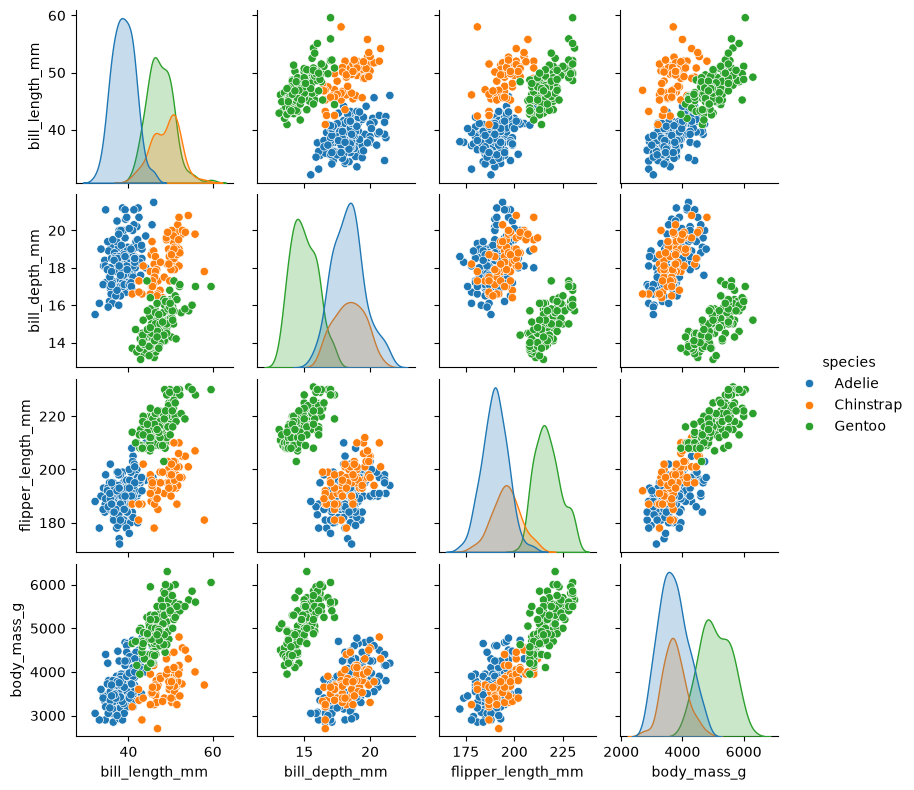

In [7]:
sns.pairplot(df, hue=target_col, vars=num_cols, height=2)
plt.show()

### 4. Encode the target **[MULTICLASS]**

The target has **3 text labels**. `LabelEncoder` is the right tool here - it is designed
for target labels. Logistic regression in scikit-learn can also take string labels
directly, but integer codes make the confusion matrix and metrics easier to work with.

In [8]:
target_encoder = LabelEncoder()
y_all = target_encoder.fit_transform(df[target_col])
class_names = target_encoder.classes_

for i, name in enumerate(class_names):
    print(i, "->", name)

0 -> Adelie
1 -> Chinstrap
2 -> Gentoo


### 5. Train Test Split

In [9]:
X = df.drop(columns=[target_col])
y = pd.Series(y_all, name=target_col)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # keeps all 3 class ratios the same in train and test
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

Train shape: (273, 6)
Test shape : (69, 6)


### 6. Identify numerical and categorical columns

| Column | Column Type | Feature Type | Preprocessing Action |
|------|------------|-------------|----------------------|
| island | Categorical | Nominal (3 classes) | One Hot Encoding |
| sex | Categorical | Binary | Map to 0 / 1 |
| bill_length_mm | Numerical | Continuous | Scaling |
| bill_depth_mm | Numerical | Continuous | Scaling |
| flipper_length_mm | Numerical | Continuous | Scaling |
| body_mass_g | Numerical | Continuous | Scaling |
| species | Categorical | Multiclass (Target) | Label Encoding |

### 7. Handling Missing Values

In [10]:
num_imputer = SimpleImputer(strategy="median")
X_train_processed[num_cols] = num_imputer.fit_transform(X_train_processed[num_cols])
X_test_processed[num_cols] = num_imputer.transform(X_test_processed[num_cols])

cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_processed[cat_cols] = cat_imputer.fit_transform(X_train_processed[cat_cols])
X_test_processed[cat_cols] = cat_imputer.transform(X_test_processed[cat_cols])

print("Missing values left (train):", X_train_processed.isnull().sum().sum())
print("Missing values left (test) :", X_test_processed.isnull().sum().sum())

Missing values left (train): 0
Missing values left (test) : 0


### 8. Outlier check

Check first, treat only if needed - don't cap blindly.

In [11]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in num_cols:
    low, high = iqr_bounds(X_train_processed[col])
    n_out = ((X_train_processed[col] < low) | (X_train_processed[col] > high)).sum()
    print(f"{col:20s} outliers: {n_out}")

bill_length_mm       outliers: 0
bill_depth_mm        outliers: 0
flipper_length_mm    outliers: 0
body_mass_g          outliers: 0


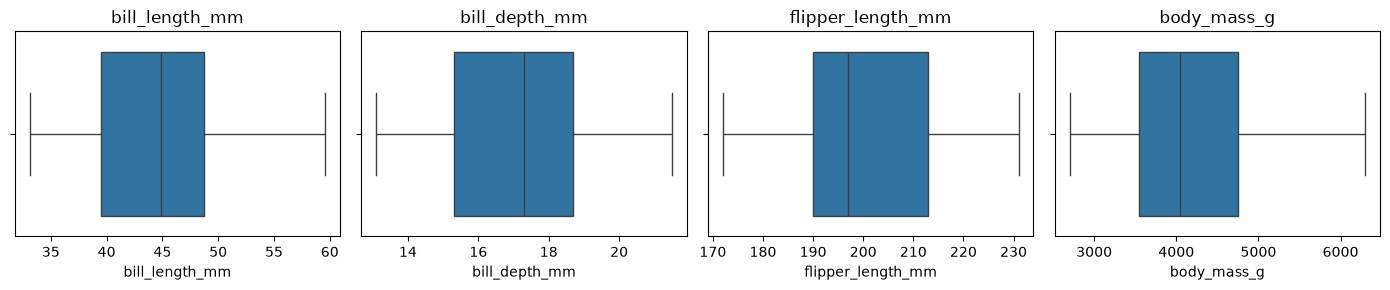

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=X_train_processed[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Decision:** no IQR outliers and the distributions are roughly symmetric → no capping and no log transform needed.

### 9. Feature engineering

In [13]:
# bill shape (long & thin vs short & deep) separates species well
for d in (X_train_processed, X_test_processed):
    d["bill_ratio"] = d["bill_length_mm"] / d["bill_depth_mm"]

num_cols_final = num_cols + ["bill_ratio"]

### 10. Encoding binary columns

In [14]:
for d in (X_train_processed, X_test_processed):
    d["sex"] = d["sex"].map({"Male": 1, "Female": 0})

assert X_train_processed["sex"].isnull().sum() == 0
assert X_test_processed["sex"].isnull().sum() == 0

### 11. Standardization - Standard Scaler

In [15]:
scaler = StandardScaler()
X_train_processed[num_cols_final] = scaler.fit_transform(X_train_processed[num_cols_final])
X_test_processed[num_cols_final] = scaler.transform(X_test_processed[num_cols_final])

X_train_processed.head()

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,bill_ratio
110,Biscoe,0.279,1.579,-0.717,0.489,1,-0.737
27,Biscoe,-1.125,0.731,-2.085,-1.327,0,-1.151
17,Torgersen,-1.763,0.631,-1.221,-1.108,0,-1.484
283,Biscoe,0.315,-1.464,1.300,0.614,0,1.202
210,Dream,0.279,1.130,-0.501,-0.857,0,-0.531


### 12. Handle imbalanced data - SMOTENC **[MULTICLASS]**

With more than two classes, SMOTENC's default strategy (`"not majority"`) oversamples
**every minority class** up to the size of the majority class.

In [16]:
print("Before SMOTENC:")
print(pd.Series(target_encoder.inverse_transform(y_train)).value_counts())

smote = SMOTENC(categorical_features=["island", "sex"], random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_processed, y_train)

print("-" * 40)
print("After SMOTENC:")
print(pd.Series(target_encoder.inverse_transform(y_train_res)).value_counts())

Before SMOTENC:
Adelie       121
Gentoo        98
Chinstrap     54
Name: count, dtype: int64
----------------------------------------
After SMOTENC:
Adelie       121
Gentoo       121
Chinstrap    121
Name: count, dtype: int64


### 13. One Hot Encoding - island

In [17]:
ohe = OneHotEncoder(drop="first", sparse_output=False)
ohe.fit(X_train_res[["island"]])

def one_hot(d):
    encoded = pd.DataFrame(
        ohe.transform(d[["island"]]),
        columns=ohe.get_feature_names_out(["island"]),
        index=d.index,
    )
    return pd.concat([d.drop(columns=["island"]), encoded], axis=1)

X_train_final = one_hot(X_train_res)
X_test_final = one_hot(X_test_processed)

print("X_train_final:", X_train_final.shape)
print("X_test_final :", X_test_final.shape)
X_train_final.head()

X_train_final: (363, 8)
X_test_final : (69, 8)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,bill_ratio,island_Dream,island_Torgersen
0,0.279,1.579,-0.717,0.489,1,-0.737,0.000,0.000
1,-1.125,0.731,-2.085,-1.327,0,-1.151,0.000,0.000
2,-1.763,0.631,-1.221,-1.108,0,-1.484,0.000,1.000
3,0.315,-1.464,1.300,0.614,0,1.202,0.000,0.000
4,0.279,1.130,-0.501,-0.857,0,-0.531,1.000,0.000


### 14. Logistic Regression - Training **[MULTICLASS]**

For more than two classes, scikit-learn's `LogisticRegression` automatically uses
**multinomial (softmax) regression**: it learns **one weight vector per class** and
turns the 3 scores into probabilities that sum to 1:

$$P(y=k \mid x) = \frac{e^{w_k \cdot x + b_k}}{\sum_{j} e^{w_j \cdot x + b_j}}$$

The predicted class is the one with the highest probability (there is no single 0.5 threshold).

In [18]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_final, y_train_res)

y_pred = model.predict(X_test_final)
y_proba = model.predict_proba(X_test_final)      # shape (n_samples, 3)

print("Coefficient matrix shape:", model.coef_.shape, "-> (n_classes, n_features)")
print("Probabilities for first 5 test rows:")
pd.DataFrame(y_proba[:5], columns=class_names).round(3)

Coefficient matrix shape: (3, 8) -> (n_classes, n_features)
Probabilities for first 5 test rows:


,Adelie,Chinstrap,Gentoo
0,0.937,0.059,0.004
1,0.992,0.007,0.001
2,0.001,0.011,0.988
3,0.020,0.005,0.975
4,0.011,0.989,0.000


### 15. Evaluation **[MULTICLASS]**

In [19]:
baseline = y_test.value_counts(normalize=True).max()
print(f"Baseline accuracy (always predict majority): {baseline:.3f}")
print(f"Model accuracy                             : {accuracy_score(y_test, y_pred):.3f}")
print(f"Macro F1                                   : {f1_score(y_test, y_pred, average='macro'):.3f}")
print(f"Weighted F1                                : {f1_score(y_test, y_pred, average='weighted'):.3f}")
print(f"ROC-AUC (one-vs-rest, macro)               : {roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro'):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=class_names))

Baseline accuracy (always predict majority): 0.435
Model accuracy                             : 1.000
Macro F1                                   : 1.000
Weighted F1                                : 1.000


ROC-AUC (one-vs-rest, macro)               : 1.000

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



> **Note:** the penguin species are very well separated by bill shape, flipper length
> and island, so a near-perfect score is expected here. Real-world multiclass problems
> are rarely this clean - the evaluation steps stay exactly the same.

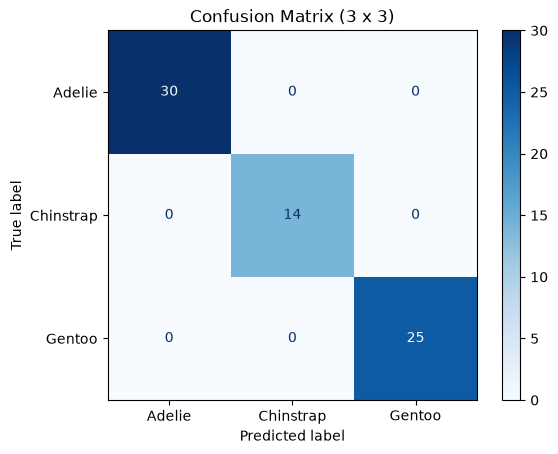

In [20]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap="Blues")
plt.title("Confusion Matrix (3 x 3)")
plt.show()

**How to read the multiclass metrics**

- Precision / recall / F1 are computed **per class** (each class vs the rest).
- **Macro average** - plain mean over classes; every class counts equally (good when small classes matter).
- **Weighted average** - mean weighted by class size.
- **ROC-AUC** needs `multi_class="ovr"` (one-vs-rest) or `"ovo"` and the full probability matrix.
- The confusion matrix is **3 × 3**: the diagonal is correct predictions, off-diagonal cells show *which* species get confused with which.

### 16. Interpreting coefficients **[MULTICLASS]**

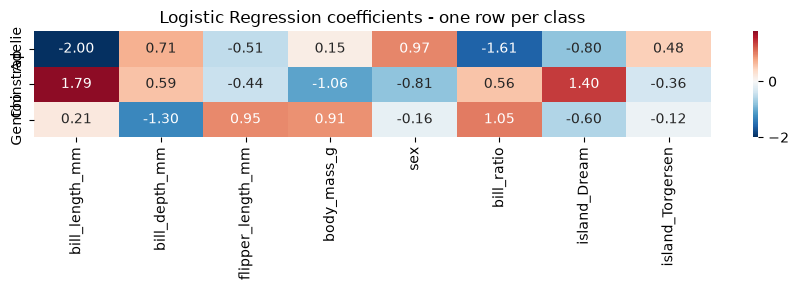

In [21]:
coef_df = pd.DataFrame(model.coef_, index=class_names, columns=X_train_final.columns)

plt.figure(figsize=(9, 3))
sns.heatmap(coef_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Logistic Regression coefficients - one row per class")
plt.tight_layout()
plt.show()

Each row tells you which features push a penguin **towards that species**. A positive
value raises that class's score relative to the others.

### 17. Binary vs Multiclass - what changes?

| Step | Binary (loan) | Multiclass (penguins) |
|---|---|---|
| Target | 2 classes, map Y/N → 1/0 | 3+ classes, `LabelEncoder` |
| Preprocessing | same | same |
| SMOTE | minority → majority | every minority class → majority |
| Model output | sigmoid → 1 probability | softmax → 1 probability per class |
| `coef_` shape | (1, n_features) | (n_classes, n_features) |
| Decision | threshold (0.5, tunable) | highest probability (argmax) |
| Confusion matrix | 2 × 2 | n × n |
| F1 / precision / recall | for the positive class | per class + macro / weighted average |
| ROC-AUC | `roc_auc_score(y, proba[:, 1])` | `roc_auc_score(y, proba, multi_class="ovr")` |

---
**End of multiclass classification example.**